# LIBERO-plus

Success per LIBERO-plus perturbation category (same 420 variants for every policy).

In [1]:
import json
import re
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle

import utils as u

FS_SMALL = 9  # pt: \small of the paper
PAGE_WIDTH = 5.5  # in: \textwidth of the paper (\linewidth of a figure)
ROOT = Path.cwd().parent
data_path = ROOT / "results"
figs_path = ROOT / "analysis/figs"
style_path = ROOT / "analysis/figure.mplstyle"

In [2]:
data = json.loads((data_path / "data.json").read_text())
figs_path.mkdir(exist_ok=True)
plt.style.use(style_path)

In [3]:
PLUS_RAMP = ["#f5f6f8", "#dcdee2", "#b9bcc2", "#8e9299", "#5f636b", "#353840"]  # neutral sequential, light -> dark

In [4]:
plus = data["libero_plus"]
rows = [(spec, re.sub(r"π([\d.]+)", r"$\\pi_{\1}$", label)) for label, _role, _run, spec in u.ranked_policies(data)]
cols = [*[short for _, short in u.PLUS_CATEGORIES], "all"]
grid = np.full((len(rows), len(cols)), np.nan)
for i, (spec, _label) in enumerate(rows):
    r = plus[spec]
    for j, (cat, _) in enumerate(u.PLUS_CATEGORIES):
        grid[i, j] = 100 * r[f"category/{cat}"]
    grid[i, -1] = 100 * r["all"]
xs = [j + (0.25 if j == len(cols) - 1 else 0) for j in range(len(cols))]

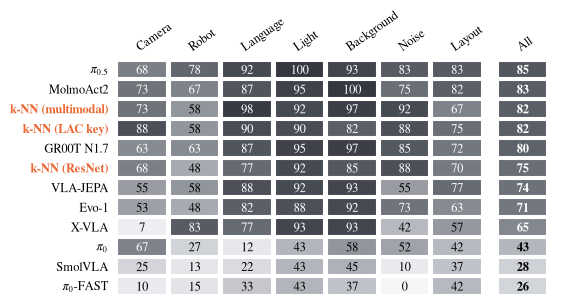

In [5]:
fig, ax = plt.subplots(figsize=(PAGE_WIDTH, 0.612 + 0.1944 * len(rows)), layout="constrained")
cmap = mpl.colors.LinearSegmentedColormap.from_list("plus", PLUS_RAMP)
for i in range(len(rows)):
    for j, x in enumerate(xs):
        v = grid[i, j]
        if np.isnan(v):
            continue
        ax.add_patch(Rectangle((x - 0.47, i - 0.45), 0.94, 0.9, facecolor=cmap(v / 100), edgecolor="white", linewidth=1.5))
        ax.text(x, i, f"{v:.0f}", ha="center", va="center_baseline", fontsize=FS_SMALL,
                color="white" if v >= 60 else "black", weight="bold" if j == len(cols) - 1 else "normal")  # fmt: skip
ax.set_xticks(xs, [c.title() for c in cols], rotation=35, ha="left", rotation_mode="anchor")
ax.xaxis.tick_top()
labels = [r[1] for r in rows]
ax.set_yticks(range(len(rows)), labels)
for tick, lab in zip(ax.get_yticklabels(), labels, strict=True):
    if lab.startswith("k-NN"):
        tick.set_color(u.Colour.KNN)
        tick.set_fontweight("bold")
ax.tick_params(length=0)
for sp in ax.spines.values():
    sp.set_visible(False)
ax.set_xlim(-0.55, xs[-1] + 0.55)
ax.set_ylim(len(rows) - 0.5, -0.5)
fig.savefig(figs_path / "libero_plus.pdf")